### 05 5 fold cross validation, ct + ht
reads: prep/  
writes: results/cv_folds.csv, cv_summary.csv, cv_metrics.png  
these are the numbers to report

#### setup

In [1]:
import os, json, time, numpy as np, pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

PREP = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/prep'
OUT  = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/results'
os.makedirs(OUT, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

K = 5
BATCH, EPOCHS, PATIENCE = 1024, 300, 20
print(device)

cuda


#### load data, unlabeled pool = all non-positive pairs

In [2]:
meta = json.load(open(f'{PREP}/meta.json'))
n_h, n_c, n_t = meta['n_h'], meta['n_c'], meta['n_t']

C_feat = torch.from_numpy(np.load(f'{PREP}/C_feat.npy')).to(device)
T_feat = torch.from_numpy(np.load(f'{PREP}/T_feat.npy')).to(device)
hc = np.load(f'{PREP}/hc_edges.npy')

# all 14166 positives back in one array, folds re-split them
ct_all = np.concatenate([np.load(f'{PREP}/{x}.npy') for x in ['ct_train','ct_val_pos','ct_test_pos']], axis=1)

# unlabeled pool = every (c,t) pair that is not a positive (same 3,095,613 rows as the csv)
pos_key = ct_all[0] * n_t + ct_all[1]
neg_key = np.setdiff1d(np.arange(n_c * n_t), pos_key)

known = torch.zeros(n_c, n_t, dtype=torch.bool, device=device)
known[torch.from_numpy(ct_all[0]).long(), torch.from_numpy(ct_all[1]).long()] = True

print(ct_all.shape, len(neg_key))

(2, 14166) 3095613


#### herb-target setup

In [3]:
H_df = pd.DataFrame(hc.T, columns=['h','c'])

def ht_keys(ct):
    j = H_df.merge(pd.DataFrame(ct.T, columns=['c','t']), on='c')
    return np.unique(j['h'].values * n_t + j['t'].values)

ht_all = ht_keys(ct_all)
ht_known = np.zeros(n_h * n_t, dtype=bool)
ht_known[ht_all] = True
ht_known = ht_known.reshape(n_h, n_t)
ht_neg = np.setdiff1d(np.arange(n_h * n_t), ht_all)

herb_cmps = [torch.from_numpy(np.unique(hc[1][hc[0] == h])).long().to(device) for h in range(n_h)]
print('ht positives', len(ht_all), 'ht negatives', len(ht_neg))

ht positives 24835 ht negatives 58307


#### model classes

In [4]:
class RelConv(nn.Module):
    def __init__(self, in_dim, out_dim, n_rel):
        super().__init__()
        self.W_rel  = nn.Parameter(torch.randn(n_rel, in_dim, out_dim) * 0.01)
        self.W_self = nn.Parameter(torch.randn(in_dim, out_dim) * 0.01)
        self.bias   = nn.Parameter(torch.zeros(out_dim))
    def forward(self, x, edge_sets):
        out = x @ self.W_self
        for r, (src, dst) in enumerate(edge_sets):
            if src.numel() == 0: continue
            m = x[src] @ self.W_rel[r]
            agg = torch.zeros(x.size(0), out.size(1), device=x.device, dtype=out.dtype)
            agg.index_add_(0, dst, m)
            deg = torch.zeros(x.size(0), device=x.device)
            deg.index_add_(0, dst, torch.ones_like(dst, dtype=torch.float))
            out = out + agg / deg.clamp(min=1).unsqueeze(1)
        return out + self.bias

class Encoder(nn.Module):
    def __init__(self, n_h, n_c, n_t, d_in_c, d_in_t, d=128, n_rel=4, dropout=0.2):
        super().__init__()
        self.herb_emb = nn.Embedding(n_h, d)
        self.proj_c = nn.Linear(d_in_c, d)
        self.proj_t = nn.Linear(d_in_t, d)
        self.l1 = RelConv(d, d, n_rel)
        self.l2 = RelConv(d, d, n_rel)
        self.drop = nn.Dropout(dropout)
        self.n_h, self.n_c, self.n_t = n_h, n_c, n_t
    def project(self, Cf, Tf):
        return torch.cat([self.herb_emb.weight, F.relu(self.proj_c(Cf)), F.relu(self.proj_t(Tf))], dim=0)
    def forward(self, Cf, Tf, edge_sets):
        x = self.project(Cf, Tf)
        x = F.relu(self.l1(x, edge_sets))
        x = self.drop(x)
        return self.l2(x, edge_sets)

class DistMult(nn.Module):
    def __init__(self, d, n_rel=1):
        super().__init__()
        self.rel = nn.Parameter(torch.randn(n_rel, d) * 0.01)
    def forward(self, hs, ht, r=0):
        return (hs * self.rel[r] * ht).sum(dim=-1)

class Model(nn.Module):
    def __init__(self, n_h, n_c, n_t, d_in_c, d_in_t, d=128):
        super().__init__()
        self.enc = Encoder(n_h, n_c, n_t, d_in_c, d_in_t, d=d, n_rel=4)
        self.dec = DistMult(d, n_rel=1)
    def encode(self, Cf, Tf, esets):
        return self.enc(Cf, Tf, esets)
    def score_ct(self, Z, c_idx, t_idx):
        return self.dec(Z[self.enc.n_h + c_idx], Z[self.enc.n_h + self.enc.n_c + t_idx])
    def scores_all(self, Z):
        n_h, n_c = self.enc.n_h, self.enc.n_c
        return (Z[n_h:n_h+n_c] * self.dec.rel[0]) @ Z[n_h+n_c:].t()

#### split, sampling, metric helpers

In [5]:
def split_eh(rng):
    p = rng.permutation(ct_all.shape[1])
    a, b = int(0.70 * len(p)), int(0.85 * len(p))
    return ct_all[:, p[:a]], ct_all[:, p[a:b]], ct_all[:, p[b:]]

def split_cd(rng):
    cs = rng.permutation(np.unique(ct_all[0]))
    a, b = int(0.70 * len(cs)), int(0.85 * len(cs))
    parts = [cs[:a], cs[a:b], cs[b:]]
    return [ct_all[:, np.isin(ct_all[0], x)] for x in parts], parts

def sample_neg_pairs(rng, n, cmps=None):
    pool = neg_key if cmps is None else neg_key[np.isin(neg_key // n_t, cmps)]
    k = rng.choice(pool, size=min(n, len(pool)), replace=False)
    return np.stack([k // n_t, k % n_t])

def make_esets(ct_tr):
    h = torch.from_numpy(hc[0]).long().to(device)
    c = torch.from_numpy(hc[1] + n_h).long().to(device)
    cc = torch.from_numpy(ct_tr[0] + n_h).long().to(device)
    tt = torch.from_numpy(ct_tr[1] + n_h + n_c).long().to(device)
    return [(h, c), (c, h), (cc, tt), (tt, cc)]

def pr_auc(sp, sn):
    y = np.r_[np.ones(len(sp)), np.zeros(len(sn))]
    return float(average_precision_score(y, np.r_[sp, sn]))

def rank_metrics(r):
    r = np.asarray(r, dtype=np.float64)
    return {'Hits@10': float((r <= 10).mean()), 'Hits@50': float((r <= 50).mean()), 'MRR': float((1 / r).mean())}

#### train one model (early stop on val pr-auc)

In [6]:
def train(ct_tr, vp, vn, seed):
    torch.manual_seed(seed)
    es = make_esets(ct_tr)
    m = Model(n_h, n_c, n_t, C_feat.shape[1], T_feat.shape[1], d=128).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-5)
    tr = torch.from_numpy(ct_tr).long().to(device)
    vp_t = torch.from_numpy(vp).long().to(device)
    vn_t = torch.from_numpy(vn).long().to(device)

    best, wait, best_ep, state = -1, 0, 0, None
    for ep in range(1, EPOCHS + 1):
        m.train()
        perm = torch.randperm(tr.shape[1], device=device)
        for i in range(0, len(perm), BATCH):
            b = perm[i:i+BATCH]
            Z = m.encode(C_feat, T_feat, es)
            t_neg = torch.randint(0, n_t, (len(b),), device=device)
            loss = -F.logsigmoid(m.score_ct(Z, tr[0, b], tr[1, b]) - m.score_ct(Z, tr[0, b], t_neg)).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()

        if ep % 2 == 0:
            m.eval()
            with torch.no_grad():
                Z = m.encode(C_feat, T_feat, es)
                pr = pr_auc(m.score_ct(Z, vp_t[0], vp_t[1]).cpu().numpy(),
                            m.score_ct(Z, vn_t[0], vn_t[1]).cpu().numpy())
            if pr > best:
                best, wait, best_ep = pr, 0, ep
                state = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    break

    m.load_state_dict(state)
    m.eval()
    with torch.no_grad():
        Z = m.encode(C_feat, T_feat, es)
    return m, Z, best, best_ep

#### eval: filtered ranking for ct, test-only pairs for ht

In [7]:
@torch.no_grad()
def eval_ct(m, Z, te, tn):
    S = m.scores_all(Z)
    c = torch.from_numpy(te[0]).long().to(device)
    t = torch.from_numpy(te[1]).long().to(device)
    s_true = S[c, t]
    rows = S[c]
    higher = rows > s_true[:, None]
    raw = 1 + higher.sum(1)
    filt = 1 + (higher & ~known[c]).sum(1)   # other known positives of the same compound don't count against it

    sn = S[torch.from_numpy(tn[0]).long().to(device), torch.from_numpy(tn[1]).long().to(device)]
    out = {'PR-AUC': pr_auc(s_true.cpu().numpy(), sn.cpu().numpy())}
    out.update(rank_metrics(filt.cpu().numpy()))
    out.update({f'{k} raw': v for k, v in rank_metrics(raw.cpu().numpy()).items()})
    return out

@torch.no_grad()
def eval_ht(m, Z, ct_tr, ct_va, ct_te):
    S = m.scores_all(Z)
    HS = torch.stack([S[c].max(0).values for c in herb_cmps]).cpu().numpy()

    # only herb-target pairs that are reachable through test edges and NOT through train/val edges
    seen = np.union1d(ht_keys(ct_tr), ht_keys(ct_va))
    test = np.setdiff1d(ht_keys(ct_te), seen)

    flat = HS.ravel()
    out = {'PR-AUC': pr_auc(flat[test], flat[ht_neg])}
    h, t = test // n_t, test % n_t
    s_true = HS[h, t]
    filt = 1 + ((HS[h] > s_true[:, None]) & ~ht_known[h]).sum(1)
    out.update(rank_metrics(filt))
    out['n_test'] = len(test)
    return out

#### cv loop: 5 folds x 2 splits

In [8]:
rows = []
keep = {}
t0 = time.time()

for k in range(K):
    rng = np.random.default_rng(100 + k)

    tr, va, te = split_eh(rng)
    vn = sample_neg_pairs(rng, 10 * va.shape[1])
    tn = sample_neg_pairs(rng, 50 * te.shape[1])
    m, Z, vbest, bep = train(tr, va, vn, seed=k)
    r = {'fold': k, 'split': 'edge_hiding', 'val PR-AUC': vbest, 'best_ep': bep}
    r.update({f'CT {a}': b for a, b in eval_ct(m, Z, te, tn).items()})
    r.update({f'HT {a}': b for a, b in eval_ht(m, Z, tr, va, te).items()})
    rows.append(r)
    if k == 0:
        keep = dict(m=m, Z=Z, te=te)
    print(f"fold {k} EH  ct prauc {r['CT PR-AUC']:.4f}  ct h@10 {r['CT Hits@10']:.4f}  ht h@10 {r['HT Hits@10']:.4f}  ep {bep}  {time.time()-t0:.0f}s")

    (tr, va, te), parts = split_cd(rng)
    vn = sample_neg_pairs(rng, 10 * va.shape[1], parts[1])
    tn = sample_neg_pairs(rng, 50 * te.shape[1], parts[2])
    m, Z, vbest, bep = train(tr, va, vn, seed=k)
    r = {'fold': k, 'split': 'compound_disjoint', 'val PR-AUC': vbest, 'best_ep': bep}
    r.update({f'CT {a}': b for a, b in eval_ct(m, Z, te, tn).items()})
    r.update({f'HT {a}': b for a, b in eval_ht(m, Z, tr, va, te).items()})
    rows.append(r)
    print(f"fold {k} CD  ct prauc {r['CT PR-AUC']:.4f}  ct h@10 {r['CT Hits@10']:.4f}  ht h@10 {r['HT Hits@10']:.4f}  ep {bep}  {time.time()-t0:.0f}s")

folds = pd.DataFrame(rows)
folds.to_csv(f'{OUT}/cv_folds.csv', index=False)

fold 0 EH  ct prauc 0.2762  ct h@10 0.3007  ht h@10 0.0843  ep 42  19s
fold 0 CD  ct prauc 0.0659  ct h@10 0.0961  ht h@10 0.0592  ep 146  54s
fold 1 EH  ct prauc 0.1799  ct h@10 0.2165  ht h@10 0.0830  ep 22  65s
fold 1 CD  ct prauc 0.1052  ct h@10 0.1341  ht h@10 0.0753  ep 96  90s
fold 2 EH  ct prauc 0.2048  ct h@10 0.3167  ht h@10 0.0747  ep 76  111s
fold 2 CD  ct prauc 0.0670  ct h@10 0.1115  ht h@10 0.0618  ep 216  157s
fold 3 EH  ct prauc 0.0956  ct h@10 0.1101  ht h@10 0.0665  ep 16  167s
fold 3 CD  ct prauc 0.0762  ct h@10 0.1244  ht h@10 0.0752  ep 198  210s
fold 4 EH  ct prauc 0.1204  ct h@10 0.2579  ht h@10 0.1188  ep 32  223s
fold 4 CD  ct prauc 0.0704  ct h@10 0.0913  ht h@10 0.0505  ep 48  240s


#### mean and std over folds

In [9]:
cols = ['CT PR-AUC','CT Hits@10','CT Hits@50','CT MRR','CT Hits@10 raw','CT Hits@50 raw','CT MRR raw',
        'HT PR-AUC','HT Hits@10','HT Hits@50','HT MRR','HT n_test']
summ = folds.groupby('split')[cols].agg(['mean','std']).T.unstack()
summ.columns = [f'{a} {b}' for a, b in summ.columns]
summ = summ[['edge_hiding mean','edge_hiding std','compound_disjoint mean','compound_disjoint std']]
summ.to_csv(f'{OUT}/cv_summary.csv')
summ.round(4)

,edge_hiding mean,edge_hiding std,compound_disjoint mean,compound_disjoint std
CT PR-AUC,0.1754,0.0715,0.0769,0.0163
CT Hits@10,0.2404,0.0826,0.1115,0.0182
CT Hits@50,0.5135,0.0711,0.2999,0.0235
CT MRR,0.1261,0.0501,0.0564,0.0074
CT Hits@10 raw,0.0747,0.0125,0.0633,0.0078
CT Hits@50 raw,0.3021,0.0392,0.2280,0.0166
CT MRR raw,0.0386,0.0052,0.0331,0.0038
HT PR-AUC,0.0675,0.0074,0.0753,0.0265
HT Hits@10,0.0855,0.0199,0.0644,0.0108
HT Hits@50,0.2421,0.0411,0.1946,0.0337


#### how much the random negative draw moves pr-auc

In [10]:
# does the random 1:50 draw from the 3M pool change the test pr-auc? same model, 10 different negative draws
m0, Z0, te0 = keep['m'], keep['Z'], keep['te']
prs = []
for s in range(10):
    tn2 = sample_neg_pairs(np.random.default_rng(1000 + s), 50 * te0.shape[1])
    prs.append(eval_ct(m0, Z0, te0, tn2)['PR-AUC'])
print('test PR-AUC over 10 negative draws: mean %.4f  std %.4f  min %.4f  max %.4f' % (np.mean(prs), np.std(prs), min(prs), max(prs)))

test PR-AUC over 10 negative draws: mean 0.2723  std 0.0042  min 0.2677  max 0.2822


#### plot

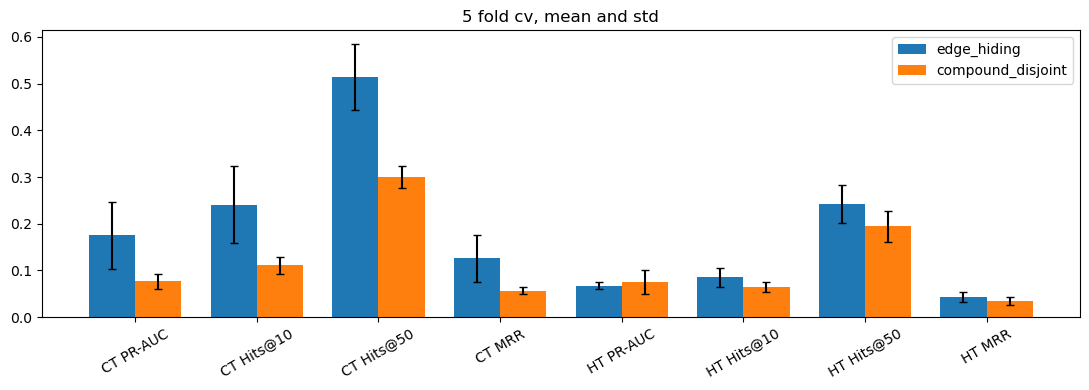

In [11]:
show = ['CT PR-AUC','CT Hits@10','CT Hits@50','CT MRR','HT PR-AUC','HT Hits@10','HT Hits@50','HT MRR']
g = folds.groupby('split')[show]
mu, sd = g.mean(), g.std()

x = np.arange(len(show))
fig, ax = plt.subplots(figsize=(11, 4))
for i, sp in enumerate(['edge_hiding', 'compound_disjoint']):
    ax.bar(x + (i - 0.5) * 0.38, mu.loc[sp], 0.38, yerr=sd.loc[sp], capsize=3, label=sp)
ax.set_xticks(x)
ax.set_xticklabels(show, rotation=30)
ax.set_title(f'{K} fold cv, mean and std')
ax.legend()
fig.tight_layout()
fig.savefig(f'{OUT}/cv_metrics.png', dpi=120)
plt.show()